# 03 Data Validation



In [9]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
FIG = "../reports/figures/"
RAW = "../data/raw/Dataset.xlsx"
from src.cleaning import CHANNEL_COLS, TARGET_COL, EXTERNAL_COLS, load_raw, clean_pipeline
from src.validation import validate, build_quality_summary, save_summary

In [10]:
clean = pd.read_csv("../data/processed/mmm_cleaned.csv", parse_dates=["month"])
raw = load_raw(RAW)
checks = validate(clean)
result = pd.DataFrame(checks).T
result["passed"] = result["passed"].map({True: "pass", False: "FAIL"})
result

,passed,detail
no_missing_values,pass,0 missing cells
no_duplicate_rows,pass,0 duplicate rows
unique_months,pass,
sorted_by_month,pass,
month_start_dates,pass,
no_missing_months,pass,"expected 36, found 36"
spend_non_negative,pass,
revenue_positive,pass,
total_equals_channel_sum,pass,
clicks_not_above_impressions,pass,


In [11]:
print("Checks passed:", sum(c["passed"] for c in checks.values()), "of", len(checks))

Checks passed: 16 of 16


## Distributions and autocorrelation

These numbers are for the modelling team. Shapiro-Wilk tests normality, and the lag-1 autocorrelation shows how strongly a variable follows its own previous month.

In [12]:
rows = []
for c in [TARGET_COL] + CHANNEL_COLS + EXTERNAL_COLS:
    s = clean[c]
    rows.append({"variable": c, "mean": s.mean(), "cv": s.std() / s.mean(), "skew": stats.skew(s),
                 "shapiro_p": stats.shapiro(s)[1], "lag1_autocorr": s.autocorr(1)})
dist = pd.DataFrame(rows).set_index("variable")
dist

,mean,cv,skew,shapiro_p,lag1_autocorr
variable,,,,,
sales_revenue_lkr,"85,091,944.111",0.090,-0.033,0.885,0.077
tv_spend_lkr,"4,360,117.833",0.198,-0.034,0.826,0.405
facebook_instagram_spend_lkr,"4,398,433.806",0.176,0.084,0.414,-0.141
google_search_spend_lkr,"3,315,364.861",0.217,0.439,0.290,0.261
youtube_spend_lkr,"2,219,825.806",0.201,0.317,0.498,0.437
radio_spend_lkr,"1,669,666.639",0.163,0.265,0.158,0.174
outdoor_spend_lkr,"2,612,716.722",0.242,0.256,0.008,0.212
average_price_index,1.105,0.057,-0.016,0.178,0.985
promotion_discount_pct,11.638,0.516,0.489,0.393,-0.177


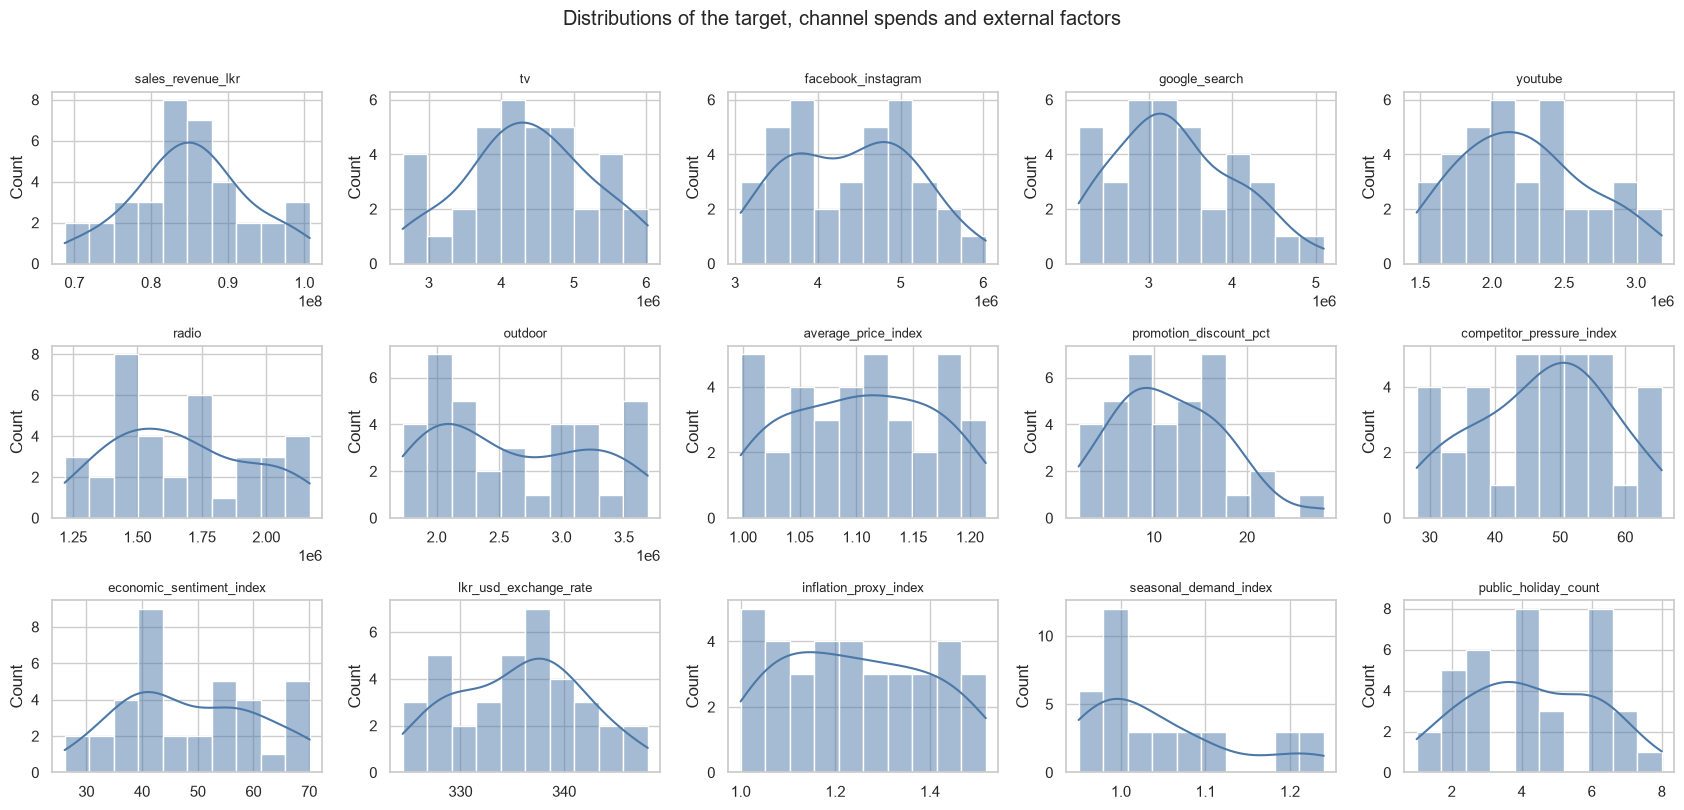

In [13]:
fig, axes = plt.subplots(3, 5, figsize=(17, 8))
for ax, c in zip(axes.ravel(), [TARGET_COL] + CHANNEL_COLS + EXTERNAL_COLS):
    sns.histplot(clean[c], kde=True, ax=ax, bins=10, color="#4c78a8")
    ax.set_title(c.replace("_spend_lkr", "").replace("_0_100", ""), fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Distributions of the target, channel spends and external factors", y=1.01)
plt.tight_layout()
plt.savefig(FIG + "03_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
log = clean_pipeline(RAW)["log"]
summary = build_quality_summary(raw, clean, log, checks)
save_summary(summary, "../reports/data_quality_summary.json")
print({k: v for k, v in summary.items() if k != "checks"})

{'dataset': 'Dataset.xlsx, sheet MMM_Data', 'period': ['2023-01-01', '2025-12-01'], 'frequency': 'monthly', 'rows_raw': 36, 'rows_clean': 36, 'columns_raw': 25, 'columns_clean': 22, 'duplicates_removed': 0, 'missing_values_found': {}, 'total_spend_rows_adjusted': 16, 'outlier_flags': 6, 'months_with_outlier_flag': 6, 'constant_columns_dropped': ['country', 'brand_category', 'region_scope', 'data_type'], 'checks_passed': 16, 'checks_total': 16}


## Conclusion

All 16 checks pass. The data has 36 consecutive months, no missing or duplicate values, non-negative spends, and funnel counts in a logical order.

Points for the modelling team:

1. There are only 36 rows, so models should stay small and be validated with walk-forward folds (see notebook 05).
2. Revenue hardly depends on the previous month (lag-1 autocorrelation 0.08). In contrast, `average_price_index` (0.99), `inflation_proxy_index` (1.00), `economic_sentiment_index_0_100` (0.79) and `lkr_usd_exchange_rate` (0.70) change slowly and move together with time.
3. Only `outdoor_spend_lkr` (p = 0.008) and `seasonal_demand_index` (p < 0.001) fail the Shapiro-Wilk normality test. Revenue does not (p = 0.89). The seasonal index is skewed because of the December peak.